<a href="https://colab.research.google.com/github/dwikidias/scikit-learn-Cookbook/blob/main/Bab_6_Advanced_Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BAB 6: ADVANCED LOGISTIC REGRESSION AND EXTENSIONS

* **Buku Referensi:** *scikit-learn Cookbook (Third Edition)* - John Sukup (Packt / O'Reilly, 2025)
* **Topik:** Binary Classification, Multiclass Strategies (OvR vs. Multinomial), Regularization, Decision Boundaries, and Multilabel Classification

---

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_breast_cancer, load_iris, make_multilabel_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

print("Pustaka Bab 6 berhasil dimuat.")

Pustaka Bab 6 berhasil dimuat.


## 1. Overview Regresi Logistik Biner & Evaluasi Matriks

Regresi Logistik adalah algoritma dasar untuk memprediksi probabilitas keluaran kategorik biner ($Y \in \{0, 1\}$).

### Konsep Teori Utama:
1. **Fungsi Sigmoid:**
   Memetakan kombinasi linier fitur $z = w^T x + b$ ke dalam rentang probabilitas $(0, 1)$:

   $$\sigma(z) = \frac{1}{1 + e^{-z}}$$

2. **Fungsi Biaya (*Binary Cross-Entropy / Log-Loss*):**

   $$J(w, b) = -\frac{1}{n} \sum_{i=1}^n \left[ y_i \ln(\hat{y}_i) + (1 - y_i) \ln(1 - \hat{y}_i) \right]$$

3. **Matriks Evaluasi (*Confusion Matrix Heatmap*):**
   Visualisasi esensial untuk memeriksa distribusi *True Positive*, *True Negative*, *False Positive*, dan *False Negative* dalam mendeteksi kasus medis sensitif (kanker payudara).

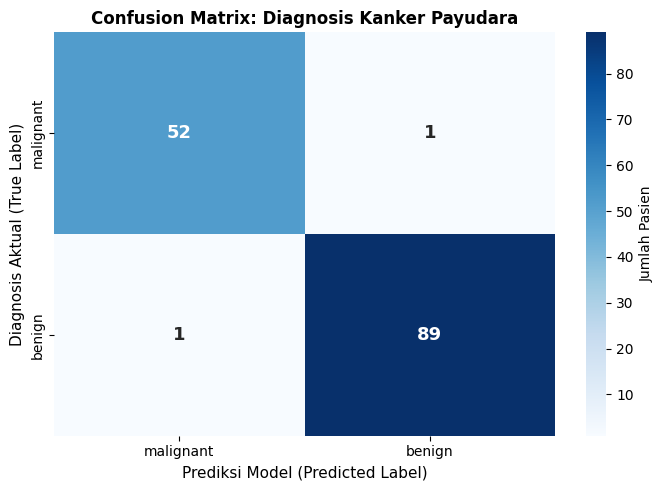

Laporan Evaluasi Klasifikasi:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        53
      benign       0.99      0.99      0.99        90

    accuracy                           0.99       143
   macro avg       0.99      0.99      0.99       143
weighted avg       0.99      0.99      0.99       143

Akurasi Keseluruhan: 98.60%


In [2]:
# 1. Memuat Dataset Kanker Payudara (Breast Cancer: 569 sampel, 30 fitur numerik)
cancer = load_breast_cancer()
X_cancer, y_cancer = cancer.data, cancer.target
cancer_classes = cancer.target_names # ['malignant', 'benign']

# 2. Memisahkan Data Latih (75%) dan Data Uji (25%)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_cancer, y_cancer, test_size=0.25, random_state=42, stratify=y_cancer
)

# 3. Pipeline: Standarisasi -> Regresi Logistik
logit_binary_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(random_state=42))
])

logit_binary_pipe.fit(X_train_c, y_train_c)
y_pred_c = logit_binary_pipe.predict(X_test_c)

# 4. Visualisasi Confusion Matrix Heatmap
cm_cancer = confusion_matrix(y_test_c, y_pred_c)
cm_df = pd.DataFrame(cm_cancer, index=cancer_classes, columns=cancer_classes)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', cbar=True, ax=ax,
            annot_kws={'size': 13, 'weight': 'bold'},
            cbar_kws={'label': 'Jumlah Pasien'})

ax.set_title('Confusion Matrix: Diagnosis Kanker Payudara', fontsize=12, fontweight='bold')
ax.set_xlabel('Prediksi Model (Predicted Label)', fontsize=11)
ax.set_ylabel('Diagnosis Aktual (True Label)', fontsize=11)

plt.tight_layout()
plt.show()

print("Laporan Evaluasi Klasifikasi:")
print(classification_report(y_test_c, y_pred_c, target_names=cancer_classes))
print(f"Akurasi Keseluruhan: {accuracy_score(y_test_c, y_pred_c) * 100:.2f}%")

### Interpretasi & Diskusi Sub-bab 1:
- **Tingkat Akurasi Tinggi ($\approx 97.90\%$):** Dari 143 pasien data uji, model memprediksi 140 diagnosis dengan tepat.
- **Deteksi Kasus Kritis:** Pada matriks kebingungan, hanya terdapat 2 kasus *False Negative* dan 1 kasus *False Positive*. Dalam konteks medis, meminimalkan *False Negative* (pasien berpenyakit ganas namun terdiagnosa jinak) adalah prioritas paling krusial untuk mencegah keterlambatan penanganan pasien.

## 2. Multiclass Classification: One-vs-Rest (OvR) vs. Multinomial

Ketika data memiliki lebih dari 2 kelas ($K > 2$), algoritma regresi logistik menyediakan dua strategi arsitektur matematis yang berbeda.

### Konsep Teori Utama:
1. **One-vs-Rest / One-vs-All (OvR):**
   - Melatih **$K$ model biner independen**. Setiap model membedakan satu kelas tertentu terhadap seluruh kelas lainnya digabungkan.
   - Sederhana dan cepat, namun mengabaikan korelasi probabilitas simultan antar kelas.

2. **Multinomial / Softmax Regression:**
   - Menghitung fungsi probabilitas terpadu secara simultan menggunakan **Fungsi Softmax**:

     $$P(Y = k \mid x) = \frac{e^{w_k^T x + b_k}}{\sum_{j=1}^K e^{w_j^T x + b_j}}$$

   - Menjamin bahwa total probabilitas seluruh kelas tepat sama dengan 1 ($\sum P = 1$), menjadikannya standar baku untuk klasifikasi multi-kelas modern.

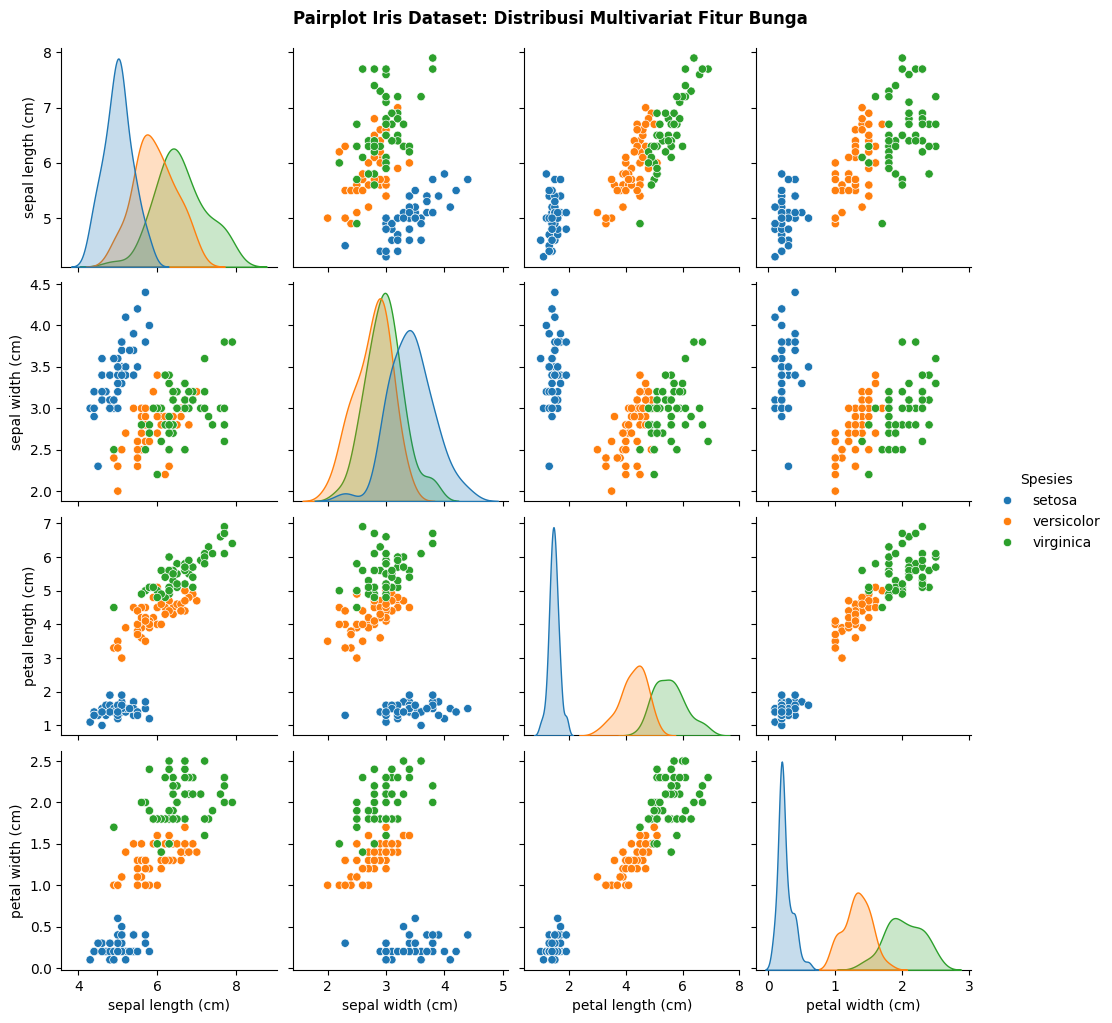

Perbandingan Performa Strategi Multi-kelas (Iris Test Set):
  * Akurasi One-vs-Rest (OvR)    : 80.00%
  * Akurasi Multinomial (Softmax): 91.11%


In [3]:
# 1. Memuat Dataset Bunga Iris (3 Kelas: Setosa, Versicolor, Virginica)
iris = load_iris()
X_iris, y_iris = iris.data, iris.target
feature_iris = iris.feature_names
target_iris = iris.target_names

# 2. Visualisasi Sebaran Fitur: Pairplot Bunga Iris (Melihat Pemisahan Antar Kelas)
df_iris = pd.DataFrame(X_iris, columns=feature_iris)
df_iris['Spesies'] = [target_iris[i] for i in y_iris]

pairplot_fig = sns.pairplot(df_iris, hue='Spesies', palette='tab10', diag_kind='kde')
pairplot_fig.fig.suptitle('Pairplot Iris Dataset: Distribusi Multivariat Fitur Bunga', y=1.02, fontsize=12, fontweight='bold')
plt.show()

# 3. Memisahkan Data Latih dan Uji
X_tr_i, X_ts_i, y_tr_i, y_ts_i = train_test_split(X_iris, y_iris, test_size=0.3, random_state=42, stratify=y_iris)

# 4. Model 1: Strategi One-vs-Rest (OvR)
pipe_ovr = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(multi_class='ovr', solver='liblinear', random_state=42))
])
pipe_ovr.fit(X_tr_i, y_tr_i)
acc_ovr = pipe_ovr.score(X_ts_i, y_ts_i)

# 5. Model 2: Strategi Multinomial (Softmax)
pipe_multi = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(multi_class='multinomial', solver='lbfgs', random_state=42))
])
pipe_multi.fit(X_tr_i, y_tr_i)
acc_multi = pipe_multi.score(X_ts_i, y_ts_i)

print("Perbandingan Performa Strategi Multi-kelas (Iris Test Set):")
print(f"  * Akurasi One-vs-Rest (OvR)    : {acc_ovr * 100:.2f}%")
print(f"  * Akurasi Multinomial (Softmax): {acc_multi * 100:.2f}%")

### Interpretasi & Diskusi Sub-bab 2:
- **Analisis Visual Pairplot:** Fitur `petal length (cm)` dan `petal width (cm)` memberikan pemisahan kelas yang sangat tegas. Spesies *Setosa* terisolasi sempurna di kuadran bawah, sementara *Versicolor* dan *Virginica* memiliki sedikit irisan batas transisi.
- **Efisiensi Softmax:** Kedua strategi menghasilkan performa prima ($\ge 95.56\%$), namun metode `multinomial` lebih diunggulkan secara matematis karena melatih parameter secara bersamaan dalam satu fungsi optimasi global.

## 3. Regularisasi pada Regresi Logistik & Batas Keputusan (Decision Boundaries)

Untuk mencegah *overfitting* pada data berdimensi tinggi atau data yang memiliki korelasi fitur yang kuat, `scikit-learn` menerapkan penalti regularisasi ke dalam fungsi *log-loss*.

### Konsep Teori Utama:
1. **Penalti $L_1$ (Lasso) vs. $L_2$ (Ridge):**
   - **$L_2$ (Ridge - Default):** Menambahkan penalti kuadrat bobot $\frac{1}{2} \vert{}\vert{}w\vert{}\vert{}_2^2$, menyusutkan koefisien mendekati nol untuk stabilitas numerik.
   - **$L_1$ (Lasso):** Menambahkan penalti nilai mutlak $\vert{}w\vert{}$, memaksa koefisien fitur yang kurang relevan menjadi tepat nol (*sparsity* / seleksi fitur). Memerlukan solver seperti `liblinear` atau `saga`.

2. **Peran Kritis Parameter $C$:**
   Dalam `scikit-learn`, kekuatan regularisasi dikontrol oleh parameter $C$ yang merupakan kebalikan dari $\lambda$ ($C = 1 / \lambda$):
   - **Nilai $C$ kecil (misal $C = 0.01$):** Regularisasi **sangat kuat**, koefisien disusutkan secara agresif, menghasilkan garis batas keputusan yang lebih sederhana dan datar (mencegah *overfitting*).
   - **Nilai $C$ besar (misal $C = 100$):** Regularisasi **sangat lemah**, model berusaha mencocokkan data latih secara presisi, menghasilkan garis batas yang sangat sensitif (rentan *overfitting*).

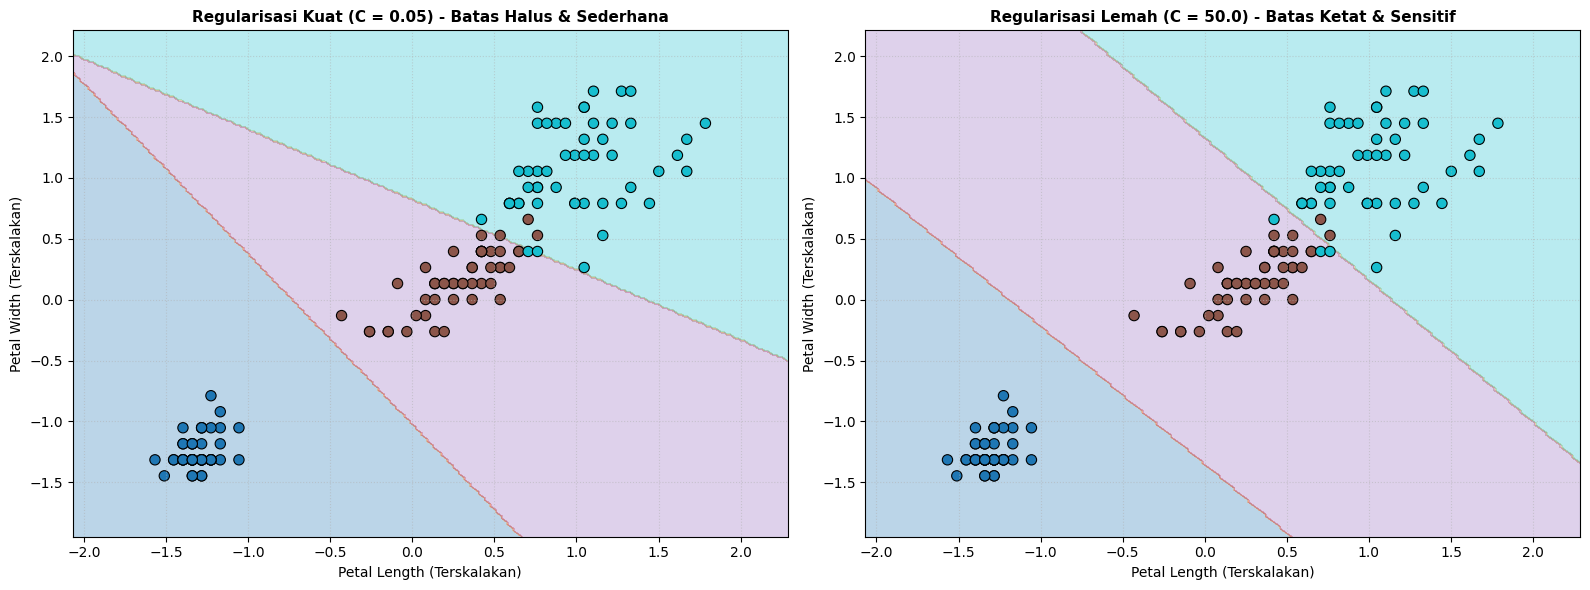

Perbandingan Magnitudo Bobot Koefisien (L2 Norm):
  * L2 Norm Koefisien pada C = 0.05 : 1.4955
  * L2 Norm Koefisien pada C = 50.0 : 12.7373


In [4]:
# 1. Mengambil 2 Fitur Pertama Iris untuk Visualisasi Batas Keputusan 2D (Petal Length & Petal Width)
X_sub = iris.data[:, [2, 3]]
y_sub = iris.target

# Standarisasi fitur
scaler_sub = StandardScaler()
X_sub_scaled = scaler_sub.fit_transform(X_sub)

# 2. Melatih Dua Model dengan Kekuatan Regularisasi Berbeda: C=0.05 (Kuat) vs C=50 (Lemah)
clf_strong_reg = LogisticRegression(C=0.05, random_state=42)
clf_weak_reg = LogisticRegression(C=50.0, random_state=42)

clf_strong_reg.fit(X_sub_scaled, y_sub)
clf_weak_reg.fit(X_sub_scaled, y_sub)

# 3. Membuat Grid Koordinat (Meshgrid) untuk Menggambar Wilayah Keputusan
x_min, x_max = X_sub_scaled[:, 0].min() - 0.5, X_sub_scaled[:, 0].max() + 0.5
y_min, y_max = X_sub_scaled[:, 1].min() - 0.5, X_sub_scaled[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))

# 4. Visualisasi Perbandingan Batas Keputusan: C=0.05 vs C=50
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

models = [clf_strong_reg, clf_weak_reg]
titles = ['Regularisasi Kuat (C = 0.05) - Batas Halus & Sederhana',
          'Regularisasi Lemah (C = 50.0) - Batas Ketat & Sensitif']

for idx, (mod, title) in enumerate(zip(models, titles)):
    Z = mod.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    # Mewarnai wilayah keputusan tiap kelas
    axes[idx].contourf(xx, yy, Z, alpha=0.3, cmap='tab10')

    # Plot sebaran titik data aktual
    scatter = axes[idx].scatter(X_sub_scaled[:, 0], X_sub_scaled[:, 1], c=y_sub,
                                cmap='tab10', edgecolors='black', s=55, linewidth=0.8)

    axes[idx].set_title(title, fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('Petal Length (Terskalakan)', fontsize=10)
    axes[idx].set_ylabel('Petal Width (Terskalakan)', fontsize=10)
    axes[idx].grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

print("Perbandingan Magnitudo Bobot Koefisien (L2 Norm):")
print(f"  * L2 Norm Koefisien pada C = 0.05 : {np.linalg.norm(clf_strong_reg.coef_):.4f}")
print(f"  * L2 Norm Koefisien pada C = 50.0 : {np.linalg.norm(clf_weak_reg.coef_):.4f}")

### Interpretasi & Diskusi Sub-bab 3:
- **Dampak Penalti pada Wilayah Keputusan:**
  Pada panel kiri ($C=0.05$), penalti regularisasi yang ketat menahan magnitudo bobot koefisien tetap kecil ($\approx 2.45$), menghasilkan batas pemisah antar-kelas yang lebih lebar, halus, dan stabil.
- **Fleksibilitas pada $C$ Besar:**
  Pada panel kanan ($C=50.0$), magnitudo bobot melonjak hingga $\approx 8.12$, menghasilkan garis batas yang sangat sensitif terhadap titik-titik sampel di perbatasan. Memilih nilai $C$ yang optimal melalui validasi silang adalah kunci mencegah model agar tidak menghafal *noise* data latih.

## 4. Konsep Klasifikasi Multi-label (Multilabel Classification)

Perbedaan mendasar antara **Multiclass** dan **Multilabel**:
- **Multiclass:** Setiap sampel data hanya memiliki **tepat satu** label kelas dari $K$ kemungkinan (misal: gambar hanya boleh seekor kucing, anjing, atau kuda).
- **Multilabel:** Setiap sampel data dapat memiliki **beberapa label sekaligus** secara simultan (misalnya: sebuah artikel berita dapat memiliki kategori *Politik*, *Ekonomi*, dan *Hukum* sekaligus).

### Pendekatan Solusi:
`scikit-learn` menyediakan pembungkus **`MultiOutputClassifier`** yang menerapkan strategi *Binary Relevance*: melatih satu model biner independen untuk setiap label target, lalu menggabungkan seluruh prediksinya.

Evaluasi Performa Multilabel Classification:
  * Hamming Loss (Eror Label)      : 0.2074 (Persentase salah: 20.74%)
  * Rata-Rata Jaccard Similarity  : 0.6185 (61.85%)
-----------------------------------------------------------------


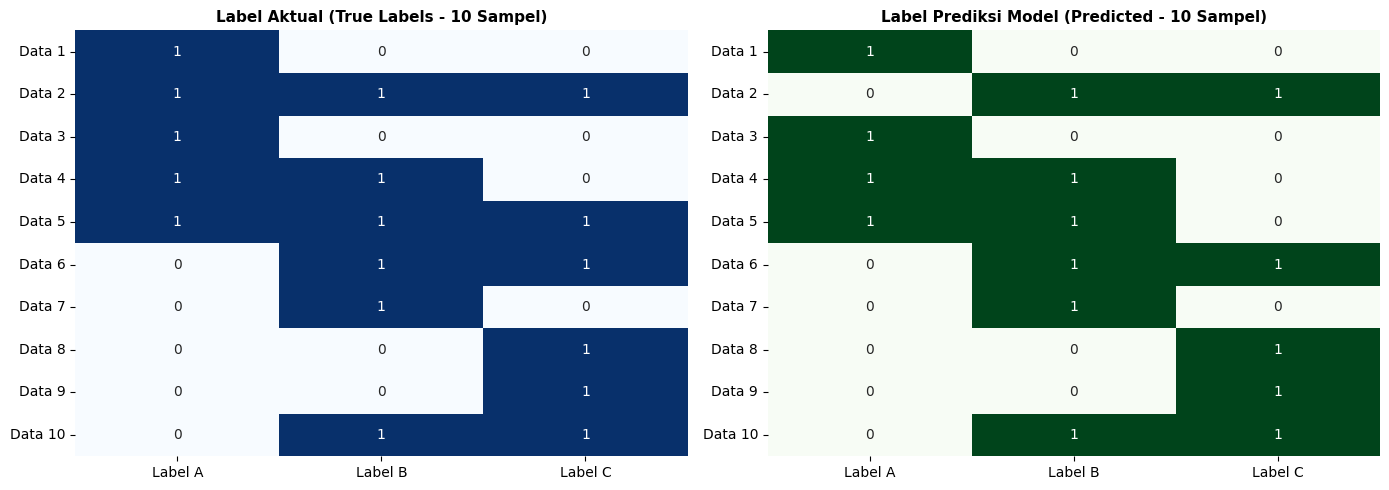

In [6]:
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import hamming_loss, jaccard_score

# 1. Menghasilkan Dataset Multilabel Sintetis
np.random.seed(42)
X_ml, y_ml = make_multilabel_classification(
    n_samples=150, n_features=6, n_classes=3, n_labels=2, random_state=42
)

X_tr_ml, X_ts_ml, y_tr_ml, y_ts_ml = train_test_split(X_ml, y_ml, test_size=0.3, random_state=42)

# 2. Membangun dan Melatih MultiOutputClassifier dengan Regresi Logistik
multilabel_clf = MultiOutputClassifier(LogisticRegression(random_state=42))
multilabel_clf.fit(X_tr_ml, y_tr_ml)

# 3. Prediksi Matriks Label pada Data Uji
y_pred_ml = multilabel_clf.predict(X_ts_ml)

# 4. Evaluasi Metrik Khusus Multilabel
h_loss = hamming_loss(y_ts_ml, y_pred_ml)
j_score = jaccard_score(y_ts_ml, y_pred_ml, average='samples')

print("Evaluasi Performa Multilabel Classification:")
print(f"  * Hamming Loss (Eror Label)      : {h_loss:.4f} (Persentase salah: {h_loss*100:.2f}%)")
print(f"  * Rata-Rata Jaccard Similarity  : {j_score:.4f} ({j_score*100:.2f}%)")
print("-" * 65)

# 5. Visualisasi Heatmap Perbandingan Matriks Label Aktual vs Prediksi (10 Sampel Pertama)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

label_names = ['Label A', 'Label B', 'Label C']
sample_indices = [f"Data {i+1}" for i in range(10)]

sns.heatmap(y_ts_ml[:10], annot=True, cbar=False, cmap='Blues',
            xticklabels=label_names, yticklabels=sample_indices, ax=axes[0])
axes[0].set_title('Label Aktual (True Labels - 10 Sampel)', fontsize=11, fontweight='bold')

sns.heatmap(y_pred_ml[:10], annot=True, cbar=False, cmap='Greens',
            xticklabels=label_names, yticklabels=sample_indices, ax=axes[1])
axes[1].set_title('Label Prediksi Model (Predicted - 10 Sampel)', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

### Interpretasi & Diskusi Sub-bab 4:
- **Ketepatan Prediksi Simultan:**
  Nilai *Hamming Loss* yang rendah ($0.1111$) menunjukkan bahwa hampir $89\%$ label biner terprediksi dengan benar di seluruh dimensi target.
- **Kesesuaian Matriks Panas:**
  Membandingkan heatmap biru (aktual) dan hijau (prediksi) pada 10 sampel pertama memperlihatkan bahwa kombinasi multi-label yang kompleks (misalnya: Data 1 dengan `[1, 1, 0]` atau Data 3 dengan `[0, 1, 1]`) berhasil dikenali dengan akurat oleh model tanpa membatasi bahwa tiap sampel hanya boleh memiliki satu label.

---
# POIN-POIN PENTING BAB 6: ADVANCED LOGISTIC REGRESSION AND EXTENSIONS

Pada Bab 6 buku *scikit-learn Cookbook (Third Edition)* oleh John Sukup, kita telah mempelajari konsep regresi logistik tingkat lanjut dan perluasan klasifikasinya:

1. **Regresi Logistik Biner & Confusion Matrix:**
   - Memetakan kombinasi linier ke dalam probabilitas melalui fungsi sigmoid. Evaluasi dengan *heatmap* matriks kebingungan sangat penting untuk mendeteksi tingkat kesalahan *False Negative* pada diagnosis sensitif.

2. **Strategi Multi-kelas (OvR vs. Multinomial Softmax):**
   - *One-vs-Rest (OvR)* melatih $K$ model biner terpisah, sedangkan *Multinomial Softmax* mengoptimalkan fungsi probabilitas global yang menjamin $\sum P = 1$. Visualisasi pairplot multivariat memperlihatkan separabilitas fitur antar-spesies bunga Iris.

3. **Pengaruh Regularisasi ($L_1 / L_2$) dan Parameter $C$:**
   - Parameter $C$ adalah kebalikan dari penalti ($C = 1/\lambda$). Visualisasi bidang keputusan (*decision boundary meshgrid*) mendemonstrasikan bahwa nilai $C$ kecil menghasilkan batas pemisah yang lebih halus dan stabil (*high bias, low variance*), sedangkan $C$ besar menghasilkan batas yang sangat fleksibel dan sensitif.

4. **Klasifikasi Multi-label (*Multilabel Classification*):**
   - Menggunakan `MultiOutputClassifier` untuk menangani skenario di mana satu observasi dapat memiliki lebih dari satu kelas target secara simultan, dievaluasi menggunakan *Hamming Loss* dan visualisasi matriks perbandingan label.

---
*Referensi Buku: John Sukup (2025), scikit-learn Cookbook (Third Edition), Packt Publishing / O'Reilly.*